In [4]:

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import heapq
import time

# Create a simulated road network
G = nx.Graph()

locations = list("ABCDEFGHIJ")
G.add_nodes_from(locations)

# Fictional road data:
# (start, end, distance_km, speed_kmh, fuel_rate_l_per_100km)
roads = [
    ("A", "B", 10, 60, 6.0),
    ("A", "C", 15, 75, 6.5),
    ("A", "D", 20, 80, 7.0),
    ("B", "E", 12, 55, 6.0),
    ("B", "F", 18, 70, 6.5),
    ("C", "E", 8, 50, 5.5),
    ("C", "F", 10, 65, 6.0),
    ("C", "G", 20, 80, 7.0),
    ("D", "G", 12, 60, 6.0),
    ("E", "H", 15, 70, 6.0),
    ("F", "H", 10, 60, 5.5),
    ("F", "I", 15, 75, 6.0),
    ("G", "I", 10, 65, 6.0),
    ("H", "J", 12, 70, 5.5),
    ("I", "J", 8, 50, 5.0)
]

for u, v, distance, speed, fuel_rate in roads:
    G.add_edge(
        u, v,
        distance=distance,
        speed=speed,
        fuel_rate=fuel_rate,
        traffic="Low"
    )

print("Number of locations:", G.number_of_nodes())
print("Number of roads:", G.number_of_edges())
print("Graph connected:", nx.is_connected(G))
print("Locations:", sorted(G.nodes()))


Number of locations: 10
Number of roads: 15
Graph connected: True
Locations: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']


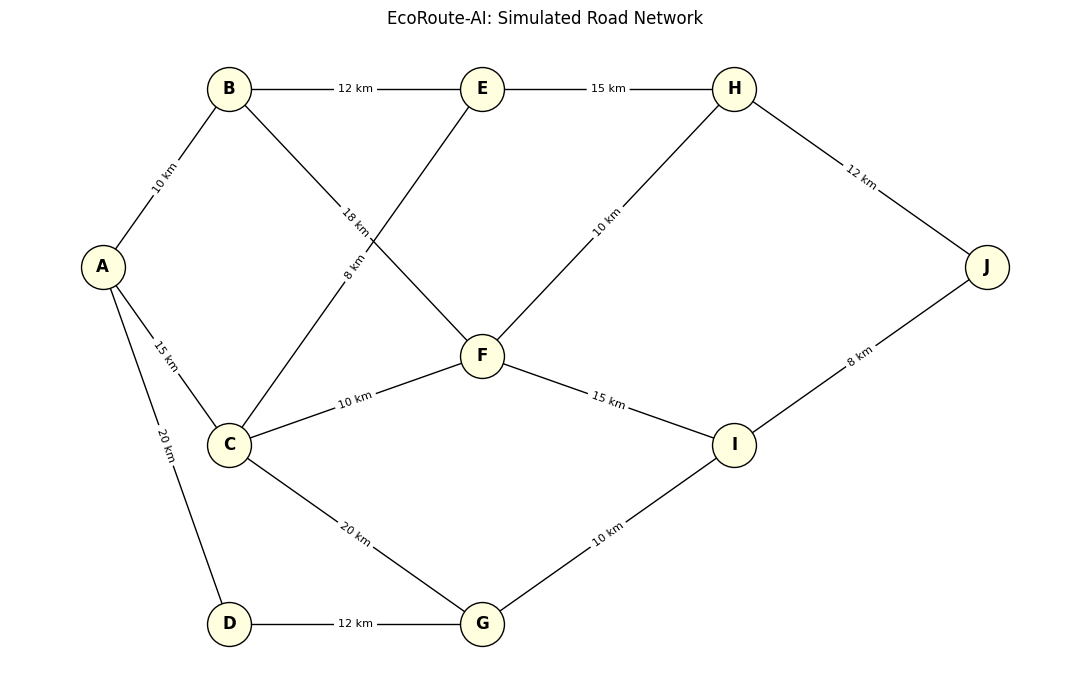

In [5]:

plt.figure(figsize=(11, 7))

# Fixed positions make the demonstration repeatable
pos = {
    "A": (0, 2),
    "B": (1, 3),
    "C": (1, 1),
    "D": (1, 0),
    "E": (3, 3),
    "F": (3, 1.5),
    "G": (3, 0),
    "H": (5, 3),
    "I": (5, 1),
    "J": (7, 2)
}

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=1000,
    node_color="lightyellow",
    edgecolors="black",
    font_weight="bold"
)

labels = {
    (u, v): f"{data['distance']} km"
    for u, v, data in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=labels,
    font_size=8
)

plt.title("EcoRoute-AI: Simulated Road Network")
plt.axis("off")
plt.tight_layout()
plt.show()


In [6]:

# Route cost configuration
TIME_WEIGHT = 0.40
FUEL_WEIGHT = 0.60

TIME_REFERENCE = 60.0  # minutes
FUEL_REFERENCE = 5.0  # litres


def get_road_metrics(data):
    """Return distance, time, fuel, and combined cost for a road."""

    distance = data["distance"]
    speed = data["speed"]
    fuel_rate = data["fuel_rate"]

    time_minutes = 60.0 * distance / speed
    fuel_litres = distance * fuel_rate / 100.0

    combined_cost = (
        TIME_WEIGHT * time_minutes / TIME_REFERENCE
        + FUEL_WEIGHT * fuel_litres / FUEL_REFERENCE
    )

    return {
        "distance": distance,
        "time": time_minutes,
        "fuel": fuel_litres,
        "cost": combined_cost
    }


def edge_cost(u, v):
    """Return the combined cost of travelling from u to v."""
    return get_road_metrics(G[u][v])["cost"]


def path_metrics(path):
    """Calculate the total metrics for a complete route."""

    total_distance = 0.0
    total_time = 0.0
    total_fuel = 0.0
    total_cost = 0.0

    for u, v in zip(path, path[1:]):
        metrics = get_road_metrics(G[u][v])

        total_distance += metrics["distance"]
        total_time += metrics["time"]
        total_fuel += metrics["fuel"]
        total_cost += metrics["cost"]

    return {
        "Route": " -> ".join(path),
        "Roads": max(0, len(path) - 1),
        "Distance (km)": round(total_distance, 2),
        "Fuel (L)": round(total_fuel, 3),
        "Time (min)": round(total_time, 2),
        "Combined Cost": round(total_cost, 4)
    }


print("Cost model configured successfully.")
print("Example road A-B:", get_road_metrics(G["A"]["B"]))


Cost model configured successfully.
Example road A-B: {'distance': 10, 'time': 10.0, 'fuel': 0.6, 'cost': 0.13866666666666666}


In [7]:

from collections import deque


def bfs_search(graph, start, goal):
    """Find a route with the fewest road connections."""

    if start not in graph or goal not in graph:
        raise ValueError("Start or destination is not in the graph.")

    queue = deque([(start, [start])])
    visited = {start}
    expanded_nodes = 0

    while queue:
        current, path = queue.popleft()
        expanded_nodes += 1

        if current == goal:
            return path, expanded_nodes

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, path + [neighbor]))

    return None, expanded_nodes


bfs_path, bfs_expanded = bfs_search(G, "A", "J")

print("BFS Route:", " -> ".join(bfs_path) if bfs_path else "No route")
print("Expanded nodes:", bfs_expanded)
print("Route metrics:", path_metrics(bfs_path) if bfs_path else None)


BFS Route: A -> B -> E -> H -> J
Expanded nodes: 10
Route metrics: {'Route': 'A -> B -> E -> H -> J', 'Roads': 4, 'Distance (km)': 49.0, 'Fuel (L)': 2.88, 'Time (min)': 46.23, 'Combined Cost': 0.6538}


In [8]:

def distance_heuristic(graph, node, goal):
    """Estimate remaining distance using the road network."""
    return nx.shortest_path_length(
        graph, source=node, target=goal, weight="distance"
    )


def greedy_best_first_search(graph, start, goal):
    """Find a heuristic-guided route; optimality is not guaranteed."""

    if start not in graph or goal not in graph:
        raise ValueError("Start or destination is not in the graph.")

    # Heap entries: (heuristic, insertion order, current node, path)
    counter = 0
    frontier = [
        (distance_heuristic(graph, start, goal), counter, start, [start])
    ]

    visited = set()
    expanded_nodes = 0

    while frontier:
        _, _, current, path = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expanded_nodes += 1

        if current == goal:
            return path, expanded_nodes

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                counter += 1
                h = distance_heuristic(graph, neighbor, goal)

                heapq.heappush(
                    frontier,
                    (h, counter, neighbor, path + [neighbor])
                )

    return None, expanded_nodes


greedy_path, greedy_expanded = greedy_best_first_search(G, "A", "J")

print(
    "Greedy Route:",
    " -> ".join(greedy_path) if greedy_path else "No route"
)
print("Expanded nodes:", greedy_expanded)
print(
    "Route metrics:",
    path_metrics(greedy_path) if greedy_path else None
)


Greedy Route: A -> D -> G -> I -> J
Expanded nodes: 5
Route metrics: {'Route': 'A -> D -> G -> I -> J', 'Roads': 4, 'Distance (km)': 50.0, 'Fuel (L)': 3.12, 'Time (min)': 45.83, 'Combined Cost': 0.6799}


In [9]:

# Find the minimum combined cost per kilometre in the graph
MIN_COST_PER_KM = min(
    edge_cost(u, v) / data["distance"]
    for u, v, data in G.edges(data=True)
)


def astar_heuristic(graph, node, goal):
    """Admissible lower bound on remaining combined route cost."""

    remaining_distance = nx.shortest_path_length(
        graph, source=node, target=goal, weight="distance"
    )

    return MIN_COST_PER_KM * remaining_distance


def astar_search(graph, start, goal):
    """Find a minimum combined-cost route using A*."""

    if start not in graph or goal not in graph:
        raise ValueError("Start or destination is not in the graph.")

    # Heap entries: (f_score, insertion order, node)
    counter = 0
    frontier = [
        (astar_heuristic(graph, start, goal), counter, start)
    ]

    best_g = {start: 0.0}
    parent = {start: None}
    expanded_nodes = 0

    while frontier:
        f_score, _, current = heapq.heappop(frontier)

        # Ignore outdated heap entries
        current_g = best_g[current]
        if f_score > current_g + astar_heuristic(
            graph, current, goal
        ) + 1e-10:
            continue

        expanded_nodes += 1

        if current == goal:
            path = []
            node = goal

            while node is not None:
                path.append(node)
                node = parent[node]

            path.reverse()
            return path, expanded_nodes

        for neighbor in graph.neighbors(current):
            new_g = current_g + edge_cost(current, neighbor)

            if new_g < best_g.get(neighbor, float("inf")):
                best_g[neighbor] = new_g
                parent[neighbor] = current

                counter += 1
                new_f = new_g + astar_heuristic(
                    graph, neighbor, goal
                )

                heapq.heappush(
                    frontier, (new_f, counter, neighbor)
                )

    return None, expanded_nodes


astar_path, astar_expanded = astar_search(G, "A", "J")

print("A* Route:", " -> ".join(astar_path) if astar_path else "No route")
print("Expanded nodes:", astar_expanded)
print("Minimum combined cost:", round(
    path_metrics(astar_path)["Combined Cost"], 4
) if astar_path else "No route")
print("Route metrics:", path_metrics(astar_path) if astar_path else None)


A* Route: A -> C -> F -> H -> J
Expanded nodes: 5
Minimum combined cost: 0.611
Route metrics: {'Route': 'A -> C -> F -> H -> J', 'Roads': 4, 'Distance (km)': 47.0, 'Fuel (L)': 2.785, 'Time (min)': 41.52, 'Combined Cost': 0.611}


In [10]:

def run_algorithm_comparison(graph, start, goal):
    algorithms = [
        ("BFS", bfs_search),
        ("Greedy Best-First", greedy_best_first_search),
        ("A*", astar_search)
    ]

    results = []

    for name, algorithm in algorithms:
        start_time = time.perf_counter()

        route, expanded = algorithm(graph, start, goal)

        elapsed_ms = (time.perf_counter() - start_time) * 1000

        if route is None:
            results.append({
                "Algorithm": name,
                "Route": "No route",
                "Roads": None,
                "Distance (km)": None,
                "Fuel (L)": None,
                "Time (min)": None,
                "Combined Cost": None,
                "Expanded Nodes": expanded,
                "Execution Time (ms)": round(elapsed_ms, 4)
            })
            continue

        metrics = path_metrics(route)

        results.append({
            "Algorithm": name,
            **metrics,
            "Expanded Nodes": expanded,
            "Execution Time (ms)": round(elapsed_ms, 4)
        })

    return pd.DataFrame(results)


comparison = run_algorithm_comparison(G, "A", "J")

display(comparison)


,Algorithm,Route,Roads,Distance (km),Fuel (L),Time (min),Combined Cost,Expanded Nodes,Execution Time (ms)
0,BFS,A -> B -> E -> H -> J,4,49.0,2.880,46.23,0.6538,10,0.0341
1,Greedy Best-First,A -> D -> G -> I -> J,4,50.0,3.120,45.83,0.6799,5,0.3067
2,A*,A -> C -> F -> H -> J,4,47.0,2.785,41.52,0.6110,5,0.4141


In [11]:

def get_road_metrics(data):
    """Calculate road metrics using the current traffic conditions."""

    distance = data["distance"]
    speed = data.get("effective_speed", data["speed"])
    fuel_rate = data.get("effective_fuel_rate", data["fuel_rate"])

    time_minutes = 60.0 * distance / speed
    fuel_litres = distance * fuel_rate / 100.0

    combined_cost = (
        TIME_WEIGHT * time_minutes / TIME_REFERENCE
        + FUEL_WEIGHT * fuel_litres / FUEL_REFERENCE
    )

    return {
        "distance": distance,
        "time": time_minutes,
        "fuel": fuel_litres,
        "cost": combined_cost
    }


def edge_cost(u, v):
    """Return the current traffic-adjusted combined cost."""
    return get_road_metrics(G[u][v])["cost"]


# Initialize every road with low traffic
TRAFFIC_FACTORS = {
    "Low": {"speed": 1.00, "fuel": 1.00},
    "Medium": {"speed": 0.75, "fuel": 1.10},
    "High": {"speed": 0.50, "fuel": 1.25}
}


def set_road_traffic(graph, u, v, level):
    """Change the traffic intensity of one road."""

    if level not in TRAFFIC_FACTORS:
        raise ValueError("Traffic must be Low, Medium, or High.")

    if not graph.has_edge(u, v):
        raise ValueError(f"No road exists between {u} and {v}.")

    factors = TRAFFIC_FACTORS[level]
    data = graph[u][v]

    data["traffic"] = level
    data["effective_speed"] = max(
        10.0, data["speed"] * factors["speed"]
    )
    data["effective_fuel_rate"] = (
        data["fuel_rate"] * factors["fuel"]
    )


for u, v in G.edges():
    set_road_traffic(G, u, v, "Low")

print("Traffic-aware cost model ready.")
print("Road F-H:", get_road_metrics(G["F"]["H"]))


Traffic-aware cost model ready.
Road F-H: {'distance': 10, 'time': 10.0, 'fuel': 0.55, 'cost': 0.13266666666666665}


In [12]:

def astar_heuristic(graph, node, goal):
    """Admissible heuristic for current traffic-adjusted costs."""

    if node == goal:
        return 0.0

    remaining_distance = nx.shortest_path_length(
        graph, source=node, target=goal, weight="distance"
    )

    min_rate = min(
        get_road_metrics(data)["cost"] / data["distance"]
        for _, _, data in graph.edges(data=True)
    )

    return remaining_distance * min_rate


In [13]:

# Scenario 1: All roads have low traffic
for u, v in G.edges():
    set_road_traffic(G, u, v, "Low")

original_path, original_expanded = astar_search(G, "A", "J")
original_metrics = path_metrics(original_path)

print("BEFORE TRAFFIC CHANGE")
print("Route:", " -> ".join(original_path))
print("Distance:", original_metrics["Distance (km)"], "km")
print("Fuel:", original_metrics["Fuel (L)"], "L")
print("Time:", original_metrics["Time (min)"], "minutes")
print("Combined cost:", original_metrics["Combined Cost"])


# Scenario 2: Heavy congestion on F-H
set_road_traffic(G, "F", "H", "High")

new_path, new_expanded = astar_search(G, "A", "J")
new_metrics = path_metrics(new_path)

print("\nAFTER TRAFFIC CHANGE")
print("Congested road: F-H")
print("Route:", " -> ".join(new_path))
print("Distance:", new_metrics["Distance (km)"], "km")
print("Fuel:", new_metrics["Fuel (L)"], "L")
print("Time:", new_metrics["Time (min)"], "minutes")
print("Combined cost:", new_metrics["Combined Cost"])

print("\nREROUTING RESULT")
if original_path != new_path:
    print("The recommended route has changed.")
else:
    print("The original route remains the lowest-cost option.")


BEFORE TRAFFIC CHANGE
Route: A -> C -> F -> H -> J
Distance: 47.0 km
Fuel: 2.785 L
Time: 41.52 minutes
Combined cost: 0.611

AFTER TRAFFIC CHANGE
Congested road: F-H
Route: A -> C -> F -> I -> J
Distance: 48.0 km
Fuel: 2.875 L
Time: 42.83 minutes
Combined cost: 0.6305

REROUTING RESULT
The recommended route has changed.


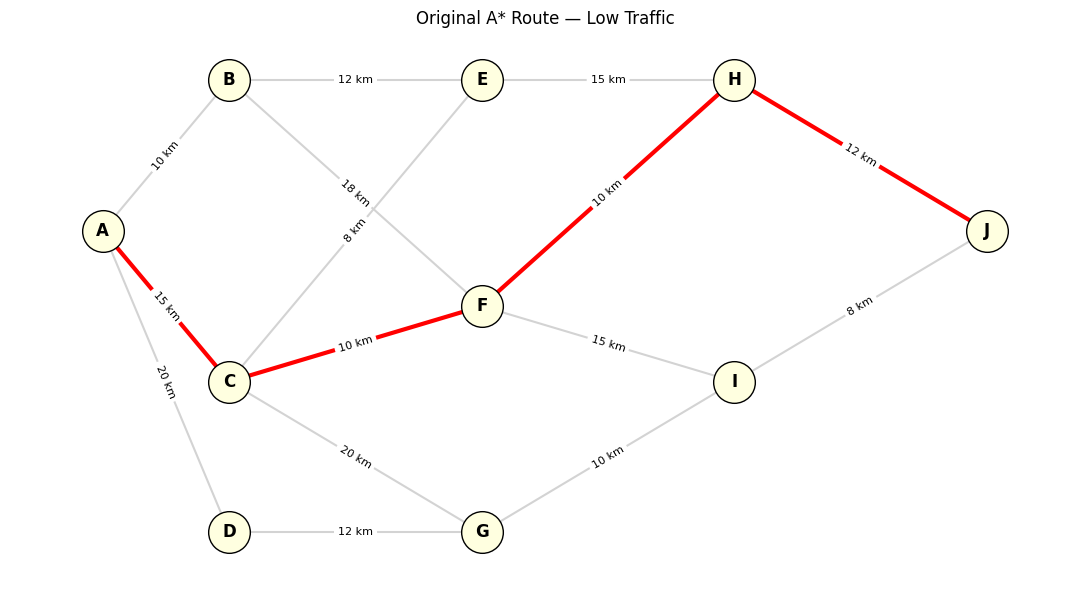

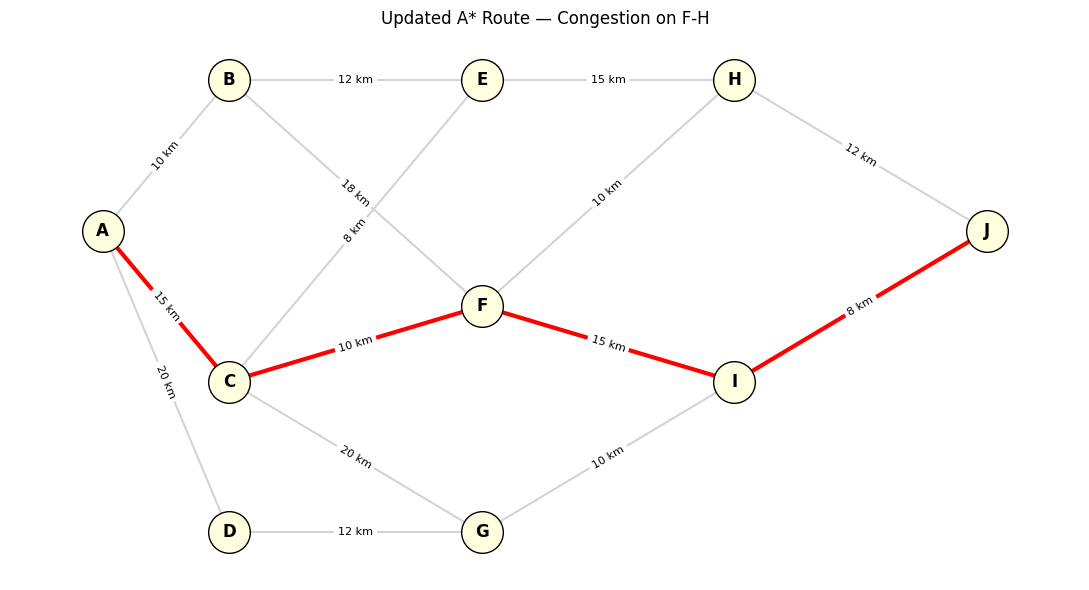

In [14]:

def draw_route(graph, route, title):
    pos = {
        "A": (0, 2),
        "B": (1, 3),
        "C": (1, 1),
        "D": (1, 0),
        "E": (3, 3),
        "F": (3, 1.5),
        "G": (3, 0),
        "H": (5, 3),
        "I": (5, 1),
        "J": (7, 2)
    }

    route_edges = list(zip(route, route[1:]))

    plt.figure(figsize=(11, 6))

    nx.draw_networkx_nodes(
        graph, pos, node_size=900,
        node_color="lightyellow", edgecolors="black"
    )
    nx.draw_networkx_edges(
        graph, pos, edge_color="lightgray", width=1.5
    )
    nx.draw_networkx_edges(
        graph, pos, edgelist=route_edges,
        edge_color="red", width=3
    )
    nx.draw_networkx_labels(graph, pos, font_weight="bold")

    labels = {
        (u, v): f"{data['distance']} km"
        for u, v, data in graph.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        graph, pos, edge_labels=labels, font_size=8
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


draw_route(G, original_path, "Original A* Route — Low Traffic")
draw_route(G, new_path, "Updated A* Route — Congestion on F-H")


Traffic level: High
Affected roads: [('F', 'H')]
Recommended route: A -> C -> F -> I -> J
Distance: 48.0 km
Estimated fuel: 2.875 L
Estimated time: 42.83 minutes
Combined cost: 0.6305
Expanded nodes: 6


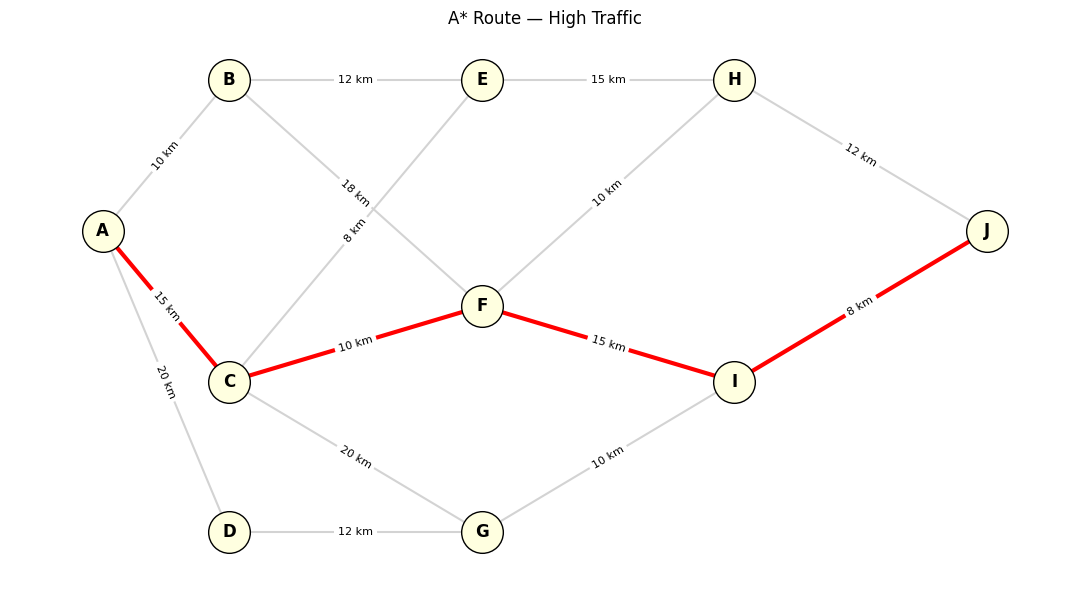

In [15]:

def simulate_traffic_scenario(start, goal, congested_roads, level):
    """Reset traffic, apply selected congestion, and rerun A*."""

    for u, v in G.edges():
        set_road_traffic(G, u, v, "Low")

    for u, v in congested_roads:
        set_road_traffic(G, u, v, level)

    route, expanded = astar_search(G, start, goal)

    if route is None:
        print("No route available.")
        return None

    metrics = path_metrics(route)

    print("Traffic level:", level)
    print("Affected roads:", congested_roads)
    print("Recommended route:", metrics["Route"])
    print("Distance:", metrics["Distance (km)"], "km")
    print("Estimated fuel:", metrics["Fuel (L)"], "L")
    print("Estimated time:", metrics["Time (min)"], "minutes")
    print("Combined cost:", metrics["Combined Cost"])
    print("Expanded nodes:", expanded)

    draw_route(G, route, f"A* Route — {level} Traffic")
    return metrics


# Example experiment
scenario_result = simulate_traffic_scenario(
    start="A",
    goal="J",
    congested_roads=[("F", "H")],
    level="High"
)


In [16]:

def compare_algorithms(start="A", goal="J"):
    algorithms = [
        ("BFS", bfs_search),
        ("Greedy Best-First", greedy_best_first_search),
        ("A*", astar_search)
    ]

    rows = []

    for name, algorithm in algorithms:
        start_time = time.perf_counter()
        route, expanded = algorithm(G, start, goal)
        elapsed_ms = (time.perf_counter() - start_time) * 1000

        if route is None:
            rows.append({
                "Algorithm": name,
                "Route": "No route",
                "Distance (km)": None,
                "Fuel (L)": None,
                "Time (min)": None,
                "Combined Cost": None,
                "Expanded Nodes": expanded,
                "Execution Time (ms)": round(elapsed_ms, 4)
            })
            continue

        metrics = path_metrics(route)

        rows.append({
            "Algorithm": name,
            "Route": metrics["Route"],
            "Distance (km)": metrics["Distance (km)"],
            "Fuel (L)": metrics["Fuel (L)"],
            "Time (min)": metrics["Time (min)"],
            "Combined Cost": metrics["Combined Cost"],
            "Expanded Nodes": expanded,
            "Execution Time (ms)": round(elapsed_ms, 4)
        })

    return pd.DataFrame(rows)


# Run the first comparison
comparison_df = compare_algorithms("A", "J")
display(comparison_df)


,Algorithm,Route,Distance (km),Fuel (L),Time (min),Combined Cost,Expanded Nodes,Execution Time (ms)
0,BFS,A -> B -> E -> H -> J,49.0,2.880,46.23,0.6538,10,0.0358
1,Greedy Best-First,A -> D -> G -> I -> J,50.0,3.120,45.83,0.6799,5,0.4837
2,A*,A -> C -> F -> I -> J,48.0,2.875,42.83,0.6305,6,1.1219


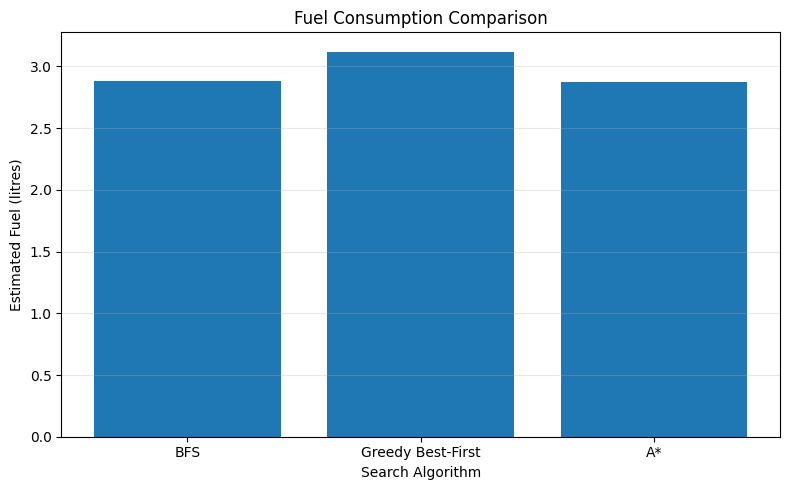

In [17]:

fuel_data = comparison_df.dropna(subset=["Fuel (L)"])

plt.figure(figsize=(8, 5))
plt.bar(fuel_data["Algorithm"], fuel_data["Fuel (L)"])
plt.title("Fuel Consumption Comparison")
plt.xlabel("Search Algorithm")
plt.ylabel("Estimated Fuel (litres)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


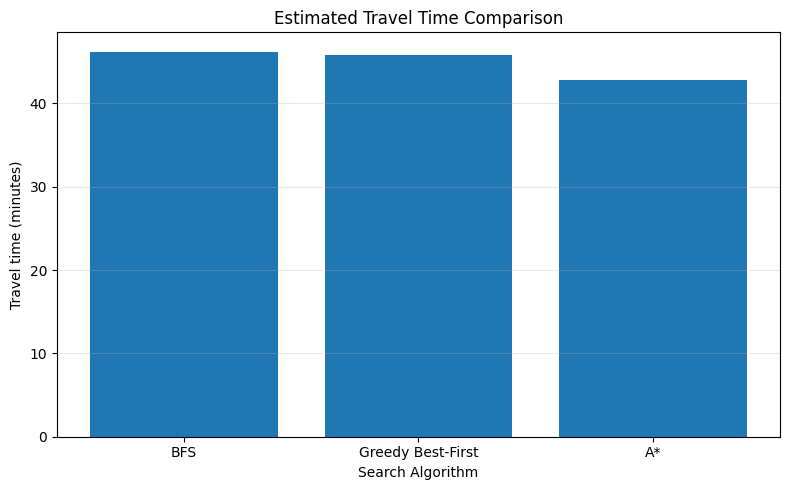

In [18]:

time_data = comparison_df.dropna(subset=["Time (min)"])

plt.figure(figsize=(8, 5))
plt.bar(time_data["Algorithm"], time_data["Time (min)"])
plt.title("Estimated Travel Time Comparison")
plt.xlabel("Search Algorithm")
plt.ylabel("Travel time (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


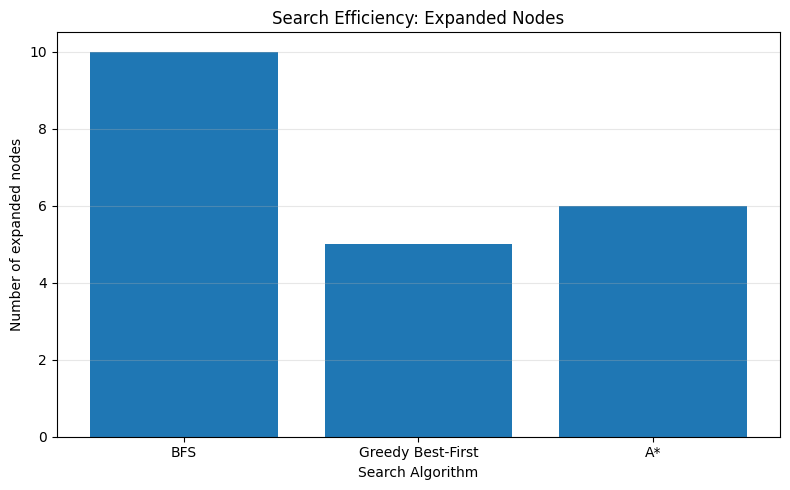

In [19]:

plt.figure(figsize=(8, 5))
plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Expanded Nodes"]
)
plt.title("Search Efficiency: Expanded Nodes")
plt.xlabel("Search Algorithm")
plt.ylabel("Number of expanded nodes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

def run_traffic_experiment(start="A", goal="J"):
    results = []

    for level in ["Low", "Medium", "High"]:
        # Apply the same traffic level to every road
        for u, v in G.edges():
            set_road_traffic(G, u, v, level)

        route, expanded = astar_search(G, start, goal)

        if route is None:
            continue

        metrics = path_metrics(route)

        results.append({
            "Traffic": level,
            "Recommended Route": metrics["Route"],
            "Distance (km)": metrics["Distance (km)"],
            "Fuel (L)": metrics["Fuel (L)"],
            "Time (min)": metrics["Time (min)"],
            "Combined Cost": metrics["Combined Cost"],
            "Expanded Nodes": expanded
        })

    return pd.DataFrame(results)


traffic_results = run_traffic_experiment("A", "J")
display(traffic_results)


,Traffic,Recommended Route,Distance (km),Fuel (L),Time (min),Combined Cost,Expanded Nodes
0,Low,A -> C -> F -> H -> J,47.0,2.785,41.52,0.6110,5
1,Medium,A -> C -> F -> H -> J,47.0,3.063,55.36,0.7367,5
2,High,A -> C -> F -> H -> J,47.0,3.481,83.03,0.9713,5


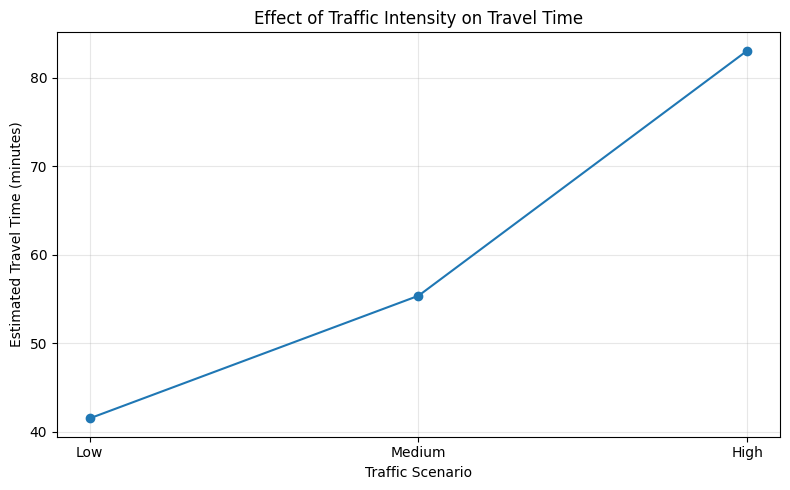

In [21]:

plt.figure(figsize=(8, 5))
plt.plot(
    traffic_results["Traffic"],
    traffic_results["Time (min)"],
    marker="o"
)
plt.title("Effect of Traffic Intensity on Travel Time")
plt.xlabel("Traffic Scenario")
plt.ylabel("Estimated Travel Time (minutes)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

# Test multiple source-destination pairs

test_cases = [
    ("A", "J"),
    ("A", "H"),
    ("B", "I"),
    ("C", "J"),
    ("D", "H")
]

algorithms = [
    ("BFS", bfs_search),
    ("Greedy Best-First", greedy_best_first_search),
    ("A*", astar_search)
]

# Reset the graph to low traffic for consistent testing
for u, v in G.edges():
    set_road_traffic(G, u, v, "Low")

all_results = []

for source, destination in test_cases:
    for algorithm_name, algorithm in algorithms:

        start_time = time.perf_counter()

        route, expanded_nodes = algorithm(
            G, source, destination
        )

        execution_time = (
            time.perf_counter() - start_time
        ) * 1000

        if route is None:
            all_results.append({
                "Source": source,
                "Destination": destination,
                "Algorithm": algorithm_name,
                "Route": "No route",
                "Distance (km)": None,
                "Fuel (L)": None,
                "Time (min)": None,
                "Combined Cost": None,
                "Expanded Nodes": expanded_nodes,
                "Execution (ms)": round(execution_time, 4)
            })
            continue

        metrics = path_metrics(route)

        all_results.append({
            "Source": source,
            "Destination": destination,
            "Algorithm": algorithm_name,
            "Route": metrics["Route"],
            "Distance (km)": metrics["Distance (km)"],
            "Fuel (L)": metrics["Fuel (L)"],
            "Time (min)": metrics["Time (min)"],
            "Combined Cost": metrics["Combined Cost"],
            "Expanded Nodes": expanded_nodes,
            "Execution (ms)": round(execution_time, 4)
        })

results_df = pd.DataFrame(all_results)

print("MULTIPLE SOURCE-DESTINATION TEST RESULTS")
display(results_df)


MULTIPLE SOURCE-DESTINATION TEST RESULTS


,Source,Destination,Algorithm,Route,Distance (km),Fuel (L),Time (min),Combined Cost,Expanded Nodes,Execution (ms)
0,A,J,BFS,A -> B -> E -> H -> J,49.0,2.880,46.23,0.6538,10,0.0218
1,A,J,Greedy Best-First,A -> D -> G -> I -> J,50.0,3.120,45.83,0.6799,5,0.2492
2,A,J,A*,A -> C -> F -> H -> J,47.0,2.785,41.52,0.6110,5,0.6299
3,A,H,BFS,A -> B -> E -> H,37.0,2.220,35.95,0.5061,8,0.0150
4,A,H,Greedy Best-First,A -> C -> F -> H,35.0,2.125,31.23,0.4632,4,0.1442
5,A,H,A*,A -> C -> F -> H,35.0,2.125,31.23,0.4632,4,0.4934
6,B,I,BFS,B -> F -> I,33.0,2.070,27.43,0.4313,8,0.0122
7,B,I,Greedy Best-First,B -> F -> I,33.0,2.070,27.43,0.4313,3,0.1003
8,B,I,A*,B -> F -> I,33.0,2.070,27.43,0.4313,3,0.5612
9,C,J,BFS,C -> E -> H -> J,35.0,2.000,32.74,0.4583,10,0.0212


In [23]:

print("BEST COMBINED-COST ROUTE FOR EACH JOURNEY")

for source, destination in test_cases:

    subset = results_df[
        (results_df["Source"] == source) &
        (results_df["Destination"] == destination)
    ].dropna(subset=["Combined Cost"])

    if subset.empty:
        print(f"{source} -> {destination}: No route found")
        continue

    best_index = subset["Combined Cost"].idxmin()
    best = subset.loc[best_index]

    print(f"\nJourney: {source} -> {destination}")
    print("Best result among tested algorithms:", best["Algorithm"])
    print("Route:", best["Route"])
    print("Distance:", best["Distance (km)"], "km")
    print("Estimated fuel:", best["Fuel (L)"], "L")
    print("Estimated time:", best["Time (min)"], "minutes")
    print("Combined cost:", best["Combined Cost"])


BEST COMBINED-COST ROUTE FOR EACH JOURNEY

Journey: A -> J
Best result among tested algorithms: A*
Route: A -> C -> F -> H -> J
Distance: 47.0 km
Estimated fuel: 2.785 L
Estimated time: 41.52 minutes
Combined cost: 0.611

Journey: A -> H
Best result among tested algorithms: Greedy Best-First
Route: A -> C -> F -> H
Distance: 35.0 km
Estimated fuel: 2.125 L
Estimated time: 31.23 minutes
Combined cost: 0.4632

Journey: B -> I
Best result among tested algorithms: BFS
Route: B -> F -> I
Distance: 33.0 km
Estimated fuel: 2.07 L
Estimated time: 27.43 minutes
Combined cost: 0.4313

Journey: C -> J
Best result among tested algorithms: A*
Route: C -> F -> H -> J
Distance: 32.0 km
Estimated fuel: 1.81 L
Estimated time: 29.52 minutes
Combined cost: 0.414

Journey: D -> H
Best result among tested algorithms: A*
Route: D -> G -> I -> J -> H
Distance: 42.0 km
Estimated fuel: 2.38 L
Estimated time: 41.12 minutes
Combined cost: 0.5597


In [24]:

output_file = "eco_route_test_results.csv"

results_df.to_csv(output_file, index=False)

print("Results saved to:", output_file)

from google.colab import files
files.download(output_file)


Results saved to: eco_route_test_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import time

# Text inputs: type the source and destination manually
source_input = widgets.Text(
    value="A",
    placeholder="Enter source (A-J)",
    description="Source:",
    style={"description_width": "initial"}
)

destination_input = widgets.Text(
    value="J",
    placeholder="Enter destination (A-J)",
    description="Destination:",
    style={"description_width": "initial"}
)

algorithm_input = widgets.Dropdown(
    options=["A*", "BFS", "Greedy Best-First", "Compare All"],
    value="A*",
    description="Algorithm:",
    style={"description_width": "initial"}
)

traffic_input = widgets.Dropdown(
    options=["Low", "Medium", "High"],
    value="Low",
    description="Traffic:",
    style={"description_width": "initial"}
)

run_button = widgets.Button(
    description="Find Route",
    button_style="primary"
)

result_output = widgets.Output()


def find_route(_):
    with result_output:
        clear_output(wait=True)

        source = source_input.value.strip().upper()
        destination = destination_input.value.strip().upper()

        # Validate user input
        if source not in G.nodes:
            print("Invalid source. Enter a valid location:", list(G.nodes))
            return

        if destination not in G.nodes:
            print("Invalid destination. Enter a valid location:", list(G.nodes))
            return

        if source == destination:
            print("Source and destination must be different.")
            return

        traffic = traffic_input.value

        # Apply the selected simulated traffic level
        for u, v in G.edges():
            set_road_traffic(G, u, v, traffic)

        algorithms = {
            "BFS": bfs_search,
            "Greedy Best-First": greedy_best_first_search,
            "A*": astar_search
        }

        selected = algorithm_input.value
        to_run = (
            list(algorithms.items())
            if selected == "Compare All"
            else [(selected, algorithms[selected])]
        )

        rows = []
        routes = {}

        for name, search_function in to_run:
            start = time.perf_counter()

            route, expanded_nodes = search_function(
                G, source, destination
            )

            elapsed_ms = (time.perf_counter() - start) * 1000

            if not route:
                print(f"{name}: No route found.")
                continue

            metrics = path_metrics(route)
            routes[name] = route

            rows.append({
                "Algorithm": name,
                "Route": metrics["Route"],
                "Roads": metrics["Roads"],
                "Distance (km)": metrics["Distance (km)"],
                "Fuel (L)": metrics["Fuel (L)"],
                "Time (min)": metrics["Time (min)"],
                "Combined Cost": metrics["Combined Cost"],
                "Expanded Nodes": expanded_nodes,
                "Execution Time (ms)": round(elapsed_ms, 4)
            })

        if not rows:
            print("No route could be calculated.")
            return

        results = pd.DataFrame(rows)

        # Select the lowest-cost route when comparing all algorithms
        if selected == "Compare All":
            best = results.loc[results["Combined Cost"].idxmin()]
            best_algorithm = best["Algorithm"]
        else:
            best_algorithm = selected
            best = results.iloc[0]

        print("=" * 45)
        print("ECOROUTE-AI: YOUR ROUTE PLAN")
        print("=" * 45)
        print(f"Source: {source}")
        print(f"Destination: {destination}")
        print(f"Traffic intensity: {traffic}")
        print(f"Selected algorithm: {best_algorithm}")
        print(f"Recommended route: {best['Route']}")
        print(f"Distance: {best['Distance (km)']} km")
        print(f"Estimated fuel: {best['Fuel (L)']} litres")
        print(f"Estimated travel time: {best['Time (min)']} minutes")
        print(f"Combined cost: {best['Combined Cost']}")
        print(f"Expanded nodes: {best['Expanded Nodes']}")
        print(f"Execution time: {best['Execution Time (ms)']} ms")

        print("\nAlgorithm comparison:")
        display(results)

        # Display the selected route on your existing graph
        draw_route(
            G,
            routes[best_algorithm],
            f"{best_algorithm}: {source} to {destination}"
        )

        filename = f"EcoRoute_{source}_to_{destination}.csv"
        results.to_csv(filename, index=False)
        print(f"\nResults saved to {filename}")


run_button.on_click(find_route)

display(widgets.VBox([
    widgets.HTML("<h2>EcoRoute-AI Route Planner</h2>"),
    source_input,
    destination_input,
    algorithm_input,
    traffic_input,
    run_button,
    result_output
]))
